# 09 南方电网电力负荷预测


本篇对应课程 `03_机器学习/09_数据挖掘案例-南方电网电力负荷预测`，依据教师《数据挖掘案例-南方电网时序预测》笔记整理。主线是：**把历史负荷变成监督学习特征，用 XGBoost 预测下一小时，再按真实时间顺序评价和部署。**

资料：[机器学习课程资料](https://pan.baidu.com/s/1NmWli9KoAeYtlpXTzhw-Jg?pwd=1234)，提取码 `1234`。

已读取教师 Markdown，并核对项目中的 `data/train.csv`、`data/test.csv` 文件名；本次未成功取得 CSV 内容，因此不报告课程真实数据的实验成绩。文中的完整代码用固定随机种子生成的**合成小时负荷**验证；真实数据入口单独保留。课程图和实验图均嵌入本 Notebook，无需旁边的图片文件。

沿用前八篇格式：全部为 Markdown 单元，Python 写在代码块中；实际练习时按顺序复制到代码单元运行。示例补充了时间验证、特征一致性和历史缺失处理；上课视频未逐段转录。


## 学习路线

| 阶段 | 需要回答的问题 | 本篇重点 |
| --- | --- | --- |
| 定义任务 | 什么时候预测，预测多远？ | 单步、多步、信息可用时点 |
| 理解数据 | 一行是不是一小时？ | 排序、时间戳冲突、缺口、负荷单位 |
| 制作特征 | 预测时能拿到哪些信息？ | 日历、滞后负荷、历史滚动统计 |
| 训练验证 | 怎样模拟未来？ | 时间切分、TimeSeriesSplit、基线对照 |
| 推理回测 | 测试期间能否使用新真值？ | 滚动一步、递归多步 |
| 工程落地 | 如何保证线上线下一致？ | 共用特征函数、保存列顺序、监控 |

本篇继续第 07 篇集成学习，把梯度提升用于回归；第 08 篇的聚类可作为后续分地区、分用电类型建模的探索方法。


## 1. 时间序列预测与四类任务

时间序列是按时间排列的观测，例如每小时负荷、每日销量、每分钟交通流量。相邻观测通常有关联，还可能包含趋势、周期、节假日效应和突发变化。预测目标是根据**预测发起时已经可用的信息**估计未来值。

| 类型 | 输入 | 输出例子 |
| --- | --- | --- |
| 单变量单步 | 历史负荷 | 下一小时负荷 |
| 单变量多步 | 历史负荷 | 未来 24 小时负荷 |
| 多变量单步 | 历史负荷、温度、日历等 | 下一小时负荷 |
| 多变量多步 | 多种历史变量、可获得的未来外部信息 | 未来 24 小时负荷 |

**本文约定：**用目标时刻 $t$ 之前已观测到的小时负荷，预测 $y_t$。例如在 10:00 的负荷已到达后预测 11:00。代码行索引是目标时刻，不是预测发起时刻。

若仪表数据延迟两小时到达，那么预测 11:00 时未必能用 10:00 的负荷；必须按实际延迟调整特征。时间早于目标不等于业务上已经可用。


## 2. 从简单基线到统计、机器学习和深度学习

基线是最低限度的比较对象。复杂模型只有在同一测试时间段、同一预测条件下优于合理基线，才有实际价值。

| 方法 | 基本思想 | 需要注意 |
| --- | --- | --- |
| 持续性预测 | $\hat y_t=y_{t-1}$ | 变化缓慢时可能很强 |
| 季节性朴素法 | 小时负荷取 $\hat y_t=y_{t-24}$ | 昨日同刻；也可比较前一周同刻 |
| 历史平均 / 滚动平均 | 使用过去整体 / 最近窗口均值 | 窗口越长通常越平滑，响应越慢 |
| 简单指数平滑 | $l_t=\alpha y_t+(1-\alpha)l_{t-1}$ | 在观测 $y_t$ 后预测下一时刻；较新观测权重更高 |
| Holt 方法 | 分别更新水平和趋势 | 趋势外推需要验证，季节扩展见 Holt-Winters |
| AR / MA / ARIMA | 用滞后值、滞后误差与差分建模 | ARIMA$(p,d,q)$ 对应 AR 阶数、差分阶数、MA 阶数 |
| 机器学习 | 将时间序列转成特征表 | 线性回归、树、随机森林、XGBoost、LightGBM 等 |
| 深度学习 | 学习序列表示和复杂依赖 | LSTM、GRU、seq2seq、Transformer 类模型等 |

AR 的简化形式为 $y_t=c+\sum_{i=1}^{p}\phi_i y_{t-i}+\epsilon_t$；MA 的简化形式为 $y_t=\mu+\epsilon_t+\sum_{j=1}^{q}\theta_j\epsilon_{t-j}$。**MA 模型中的“移动平均”是滞后误差项模型，不是 pandas 的滚动均值。**

不能把所有统计方法都概括为相同的平稳性要求，也不能先验断定机器学习必然更准。样本长度、季节性、预测跨度、外部变量和验证方式都会影响结果。


## 3. 把时间序列转成监督学习表

每个目标时刻对应一行：日历和历史信息是 $X_t$，该时刻的负荷是 $y_t$。模型学习 $\hat y_t=f(X_t)$。

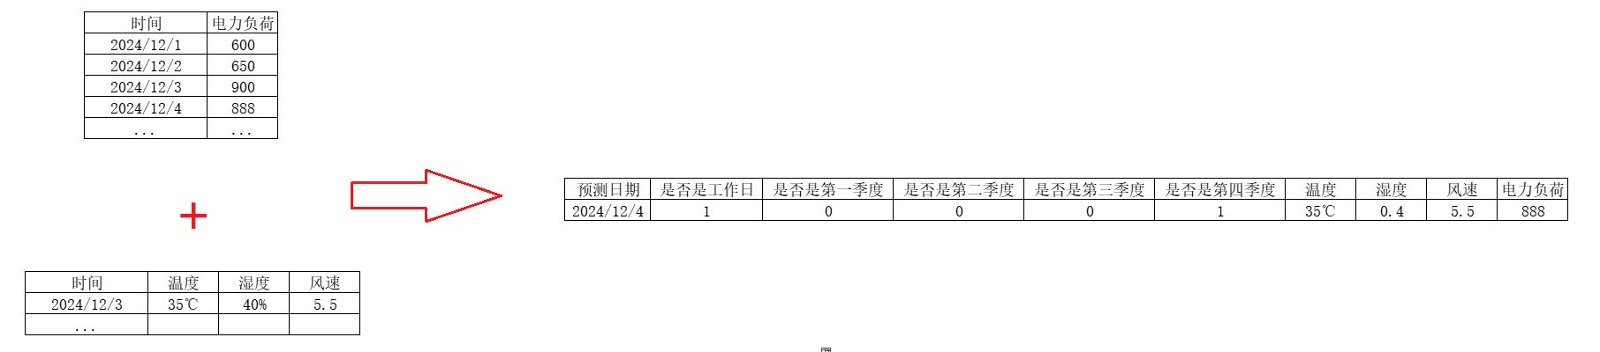

*课程图展示把日历和天气等信息合并成二维表的思路。实际使用时必须注明每个外部变量对应的时间及可用时点；图中示例不构成允许使用未来实测天气的依据。*

例如预测 8 月 1 日 03:00，可以使用目标小时、月份、前 1/2/3 小时负荷、7 月 31 日 03:00 负荷。**8 月 1 日 03:00 的真实负荷只作标签和事后评价，不能作为输入。**

加入更多列不一定更好：无关变量、错误时间对齐和泄漏特征会让离线结果失去意义。


## 4. 项目目标、字段与目录

教师项目的基础数据只有两列：

| 字段 | 含义 | 本篇处理 |
| --- | --- | --- |
| `time` | 负荷记录时间 | 保持 `datetime`，排序后作为时间索引 |
| `power_load` | 该时刻负荷 | 连续数值，作为回归标签和历史特征来源 |

课程摘录未给出可核验的负荷计量单位，不能自行写成 MW 或 kWh。真实数据应先确认单位、采样方式、时区和时间戳代表区间起点还是终点；负荷与区间电量也要区分。

建议结构：

```text
load_predict_project/
├─ data/       train.csv、test.csv
├─ log/        训练与预测日志
├─ model/      模型、特征约定、评估摘要
├─ src/        数据处理、训练、预测入口
└─ utils/      公共工具
```

教学示例统一按**无时区、整点、小时采样**处理。实际有时区的数据应先统一时区；跨夏令时地区不能直接假定每天总有 24 个本地小时。


## 5. 数据清洗：先确定“一行就是一小时”

`.shift(1)` 只移动一行。只有数据已经补成规则小时网格，才可以把它解释为“前一小时”。缺了 10:00 后直接移动，11:00 的前一行可能是 09:00。

清洗顺序：

1. 检查字段、解析时间和数值。
2. 按时间排序，删除相同时间且负荷相同的重复记录。
3. 同一时间出现不同负荷时明确报错，等待核对采集规则。
4. 建立小时网格，把未记录的小时留为缺失。
5. 在特征制作后丢弃历史不足的训练行；线上缺历史则明确报错。

这里不自动插值。线性插值、`bfill` 或居中滚动窗口可能读取未来；向前填充虽然是因果操作，也会改变负荷的含义，必须结合缺口长度和业务规则使用。

```python
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV
from xgboost import XGBRegressor

plt.rcParams["font.sans-serif"] = ["Microsoft YaHei", "SimHei", "DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False

def normalize_hourly(frame):
    required = {"time", "power_load"}
    if not required.issubset(frame.columns):
        raise ValueError(f"缺少字段：{required - set(frame.columns)}")
    data = frame.loc[:, ["time", "power_load"]].copy()
    if data.empty:
        raise ValueError("数据为空")
    data["time"] = pd.to_datetime(data["time"], errors="raise")
    if data["time"].isna().any() or data["time"].dt.tz is not None:
        raise ValueError("时间不能为空；本示例要求先转换成统一的无时区时间")
    if not data["time"].eq(data["time"].dt.floor("h")).all():
        raise ValueError("存在非整点记录，请先核对采样频率")
    data["power_load"] = pd.to_numeric(data["power_load"], errors="raise")
    known = data["power_load"].dropna().to_numpy(dtype=float)
    if not np.isfinite(known).all() or (known < 0).any():
        raise ValueError("负荷包含无穷值或负值，请核对单位及采集口径")
    conflicts = data.groupby("time")["power_load"].nunique(dropna=False)
    if conflicts.gt(1).any():
        raise ValueError("同一时间存在不同负荷，不能静默删除")
    data = data.sort_values("time").drop_duplicates("time")
    result = data.set_index("time").asfreq("h")
    return result.astype({"power_load": "float64"})
```

依赖为 `numpy pandas matplotlib scikit-learn xgboost joblib`，使用与当前 Python 兼容的版本。本篇验证环境为 Python 3.13、XGBoost 3.1；课程中的 `xgboost==1.2.0` 是旧环境示例，不能直接套用到新 Python。


## 6. 离线演示数据与课程数据入口

下面主动生成 365 天、8760 个小时的合成负荷，包含日周期、周末效应、缓慢趋势、年周期与随机波动。数值单位设为“演示负荷单位”。**它不是南方电网真实数据，也不用于证明模型在真实项目上的效果。**

```python
def make_demo_load(seed=42):
    rng = np.random.default_rng(seed)
    times = pd.date_range("2024-01-01", periods=365 * 24, freq="h")
    position = np.arange(len(times))
    hour = times.hour.to_numpy()
    day = position / 24
    weekend = (times.dayofweek >= 5).astype(float)
    daily = 100 * np.sin(2 * np.pi * (hour - 7) / 24)
    daily += 35 * np.sin(4 * np.pi * (hour - 3) / 24)
    seasonal = 45 * np.sin(2 * np.pi * day / 365)
    innovations = rng.normal(0, 12, len(times))
    noise = np.zeros(len(times))
    for i in range(1, len(times)):
        noise[i] = 0.65 * noise[i - 1] + innovations[i]
    load = 700 + daily + seasonal + 0.08 * day - 55 * weekend + noise
    return pd.DataFrame({"time": times, "power_load": load})

hourly = normalize_hourly(make_demo_load())
data_source = "合成小时负荷（随机种子42）"
print(data_source, hourly.shape, hourly.index.min(), hourly.index.max())

# 课程文件入口仅检查存在性，不静默替换上述演示数据。
course_train_path = Path("data/train.csv")
course_test_path = Path("data/test.csv")
if course_train_path.is_file() and course_test_path.is_file():
    course_train_hourly = normalize_hourly(pd.read_csv(course_train_path))
    course_test_hourly = normalize_hourly(pd.read_csv(course_test_path))
    print("课程数据已读取；按第22节说明另行划分训练、验证与测试。")
else:
    print("未找到课程CSV；当前执行的是明确标注的合成数据演示。")
```

取得课程数据后，先检查两个文件的时间范围。测试文件可能包含预测起点之前的历史上下文，不能把这些上下文行全部作为待评价目标。


## 7. 数据探索：分布、小时、月份与周末

教师重点观察负荷直方图、各小时均值、各月份均值，以及工作日和周末差别。探索图能提出特征假设，却不能证明因果关系；“周末”也不等于法定节假日，中国调休工作日需要单独的日历信息。

```python
# 探索只看早期数据，避免借最终测试集来反复选择特征。
eda = hourly.iloc[:int(len(hourly) * 0.70)].copy()
print("缺失小时：", eda["power_load"].isna().sum())
print(eda["power_load"].describe().round(2))

fig, axes = plt.subplots(2, 2, figsize=(12, 7))
eda["power_load"].hist(bins=35, ax=axes[0, 0], color="#3b82f6")
axes[0, 0].set_title("负荷分布")
eda.groupby(eda.index.hour)["power_load"].mean().plot(
    ax=axes[0, 1], marker="o", color="#2563eb")
axes[0, 1].set_title("各小时平均负荷")
eda.groupby(eda.index.month)["power_load"].mean().plot(
    ax=axes[1, 0], marker="o", color="#0d9488")
axes[1, 0].set_title("各月份平均负荷")
weekend_mean = eda.groupby(eda.index.dayofweek >= 5)["power_load"].mean()
weekend_mean.index = ["周一至周五", "周六与周日"]
weekend_mean.plot.bar(ax=axes[1, 1], rot=0, color=["#3b82f6", "#f59e0b"])
axes[1, 1].set_title("工作日与周末均值")
for ax in axes.flat:
    ax.set_ylabel("演示负荷单位")
fig.suptitle("合成数据：前70%时间段的数据探索")
fig.tight_layout()
plt.show()
```

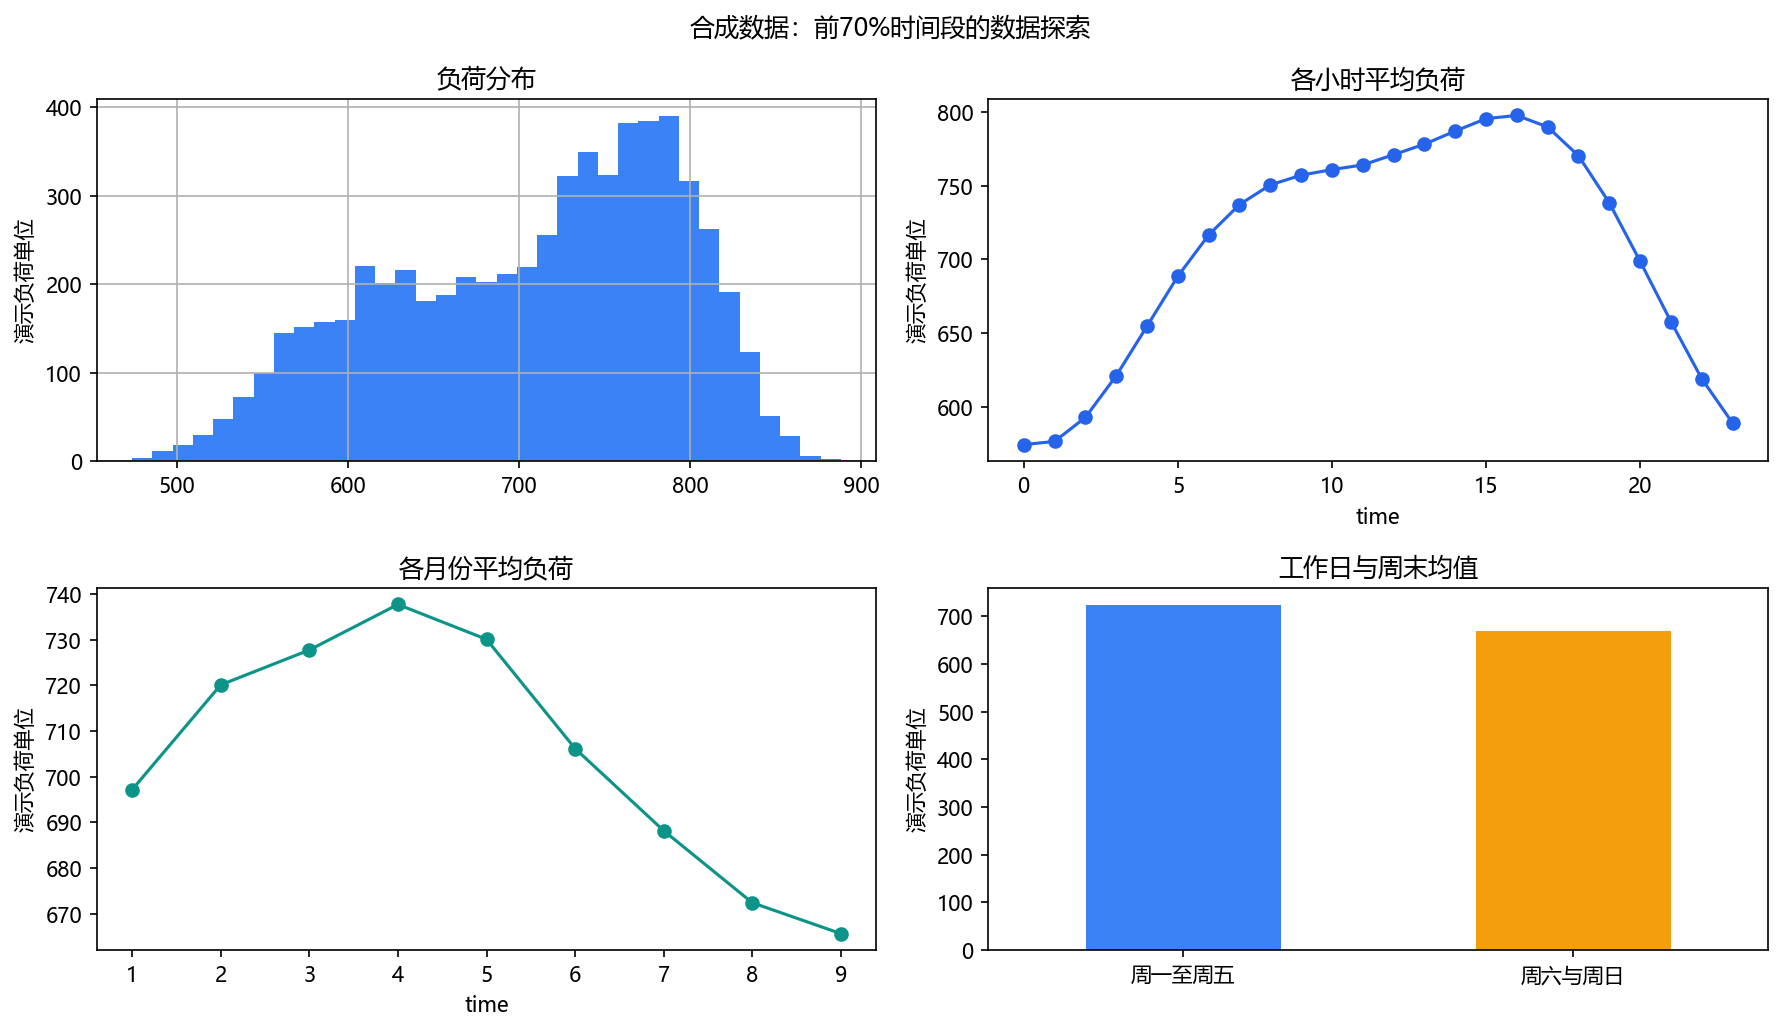

季节平均值还混合了趋势、天气和样本构成。月份均值不同，不意味着只加月份列就能准确预测未来。


### 7.1 用小例子检查缺口与冲突

```python
gap_input = pd.DataFrame({
    "time": ["2024-01-01 00:00", "2024-01-01 02:00", "2024-01-01 02:00"],
    "power_load": [100, 120, 120],
})
gap_checked = normalize_hourly(gap_input)
assert len(gap_checked) == 3
assert pd.isna(gap_checked.loc["2024-01-01 01:00", "power_load"])
assert pd.isna(gap_checked["power_load"].shift(1).iloc[-1])

conflict_input = gap_input.copy()
conflict_input.loc[2, "power_load"] = 999
try:
    normalize_hourly(conflict_input)
except ValueError as exc:
    print("预期的冲突提示：", exc)
else:
    raise AssertionError("时间戳冲突没有被识别")
```

缺失并未消失，而是显式保留在 01:00。这样不会把 00:00 的负荷误叫成 02:00 的“前一小时”。


## 8. 特征设计：日历与严格滞后的历史

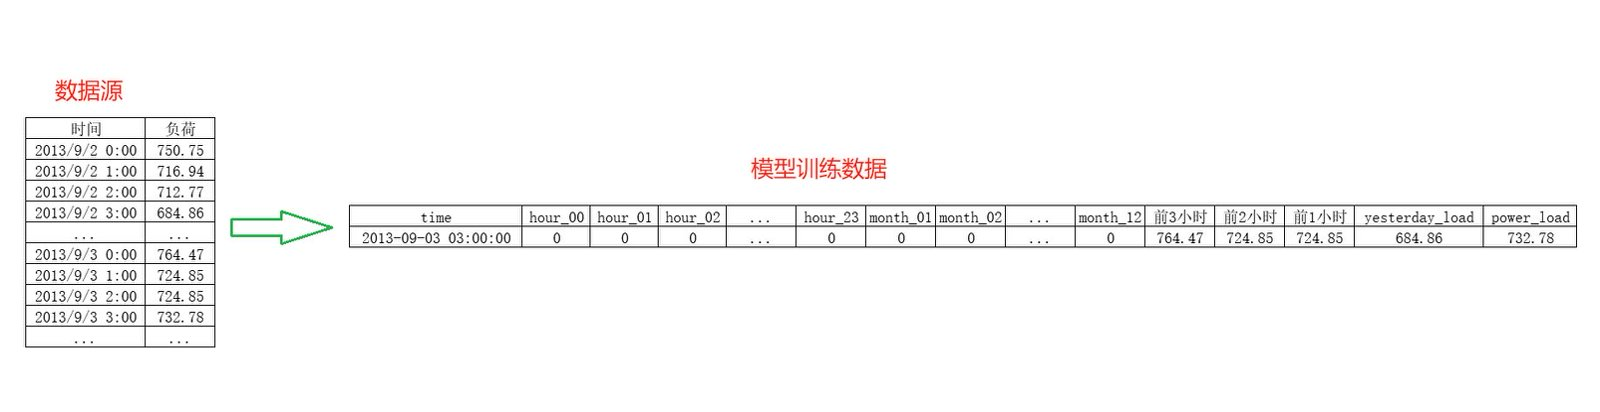

*课程图说明日历编码、前几小时负荷和昨日同刻负荷的组合。截图只作为结构示意，03:00 的小时编码应由实际时间计算为 `hour_03=1`，不要照抄图中的数字。*

| 特征 | 计算方式 | 预测目标 $y_t$ 时是否可用 |
| --- | --- | --- |
| 小时、月份 | 从目标时间 $t$ 提取，固定类别 one-hot | 可用，未来日历是已知的 |
| 周末标记 | 目标时间的星期 | 可用，但不包含调休规则 |
| `lag_1/2/3` | $y_{t-1},y_{t-2},y_{t-3}$ | 历史已到达时可用 |
| `yesterday_load` | $y_{t-24}$ | 小时网格、同刻观测可用时可用 |
| 过去24小时均值 | $y_{t-24},\ldots,y_{t-1}$ 的均值 | 先 shift，再 rolling |
| 过去24小时标准差 | 同一历史窗口的波动 | 窗口必须完整 |

本示例用 24 个小时列、12 个月份列、1 个周末列、4 个滞后列和 2 个统计列，共 **43 个特征**。固定类别可以避免“训练期没有某月份，预测时列数突然变了”，但不能解决模型没见过该月份的泛化问题。

树模型通常不要求特征标准化。若换成线性回归或 SVR，需把标准化等拟合步骤放在训练折内的 Pipeline 中。


## 9. 统一特征函数

训练和预测共同调用同一个函数，避免两份逻辑对列名、顺序、窗口含义产生分歧。

```python
HOUR_COLS = [f"hour_{h:02d}" for h in range(24)]
MONTH_COLS = [f"month_{m:02d}" for m in range(1, 13)]
HISTORY_COLS = [
    "lag_1", "lag_2", "lag_3", "yesterday_load",
    "roll24_mean", "roll24_std",
]
FEATURE_COLUMNS = HOUR_COLS + MONTH_COLS + ["is_weekend"] + HISTORY_COLS

def build_features(load):
    if not isinstance(load.index, pd.DatetimeIndex) or load.empty:
        raise ValueError("需要非空DatetimeIndex")
    if load.index.tz is not None:
        raise ValueError("请先统一为本例使用的无时区时间")
    if not load.index.is_unique or not load.index.is_monotonic_increasing:
        raise ValueError("时间索引必须唯一且升序")
    expected = pd.date_range(load.index.min(), load.index.max(), freq="h")
    if not load.index.equals(expected):
        raise ValueError("请先用normalize_hourly建立规则小时网格")
    idx = load.index
    hour = pd.Series(pd.Categorical(idx.hour, categories=range(24)), index=idx)
    month = pd.Series(pd.Categorical(idx.month, categories=range(1, 13)), index=idx)
    hour_dummy = pd.get_dummies(hour, dtype=float)
    month_dummy = pd.get_dummies(month, dtype=float)
    hour_dummy.columns = HOUR_COLS
    month_dummy.columns = MONTH_COLS
    features = pd.concat([hour_dummy, month_dummy], axis=1)
    features["is_weekend"] = (idx.dayofweek >= 5).astype(float)
    for k in (1, 2, 3):
        features[f"lag_{k}"] = load.shift(k)
    features["yesterday_load"] = load.shift(24)
    past = load.shift(1)
    features["roll24_mean"] = past.rolling(24, min_periods=24).mean()
    features["roll24_std"] = past.rolling(24, min_periods=24).std(ddof=0)
    return features.loc[:, FEATURE_COLUMNS].astype("float64")

def build_supervised(hourly_frame):
    features = build_features(hourly_frame["power_load"])
    table = features.join(hourly_frame["power_load"])
    # 缺失目标或窗口历史不足，都不进入当前训练样本。
    return table.dropna(subset=FEATURE_COLUMNS + ["power_load"])

table = build_supervised(hourly)
assert len(FEATURE_COLUMNS) == 43
print("特征表：", table.shape)
print(table[["lag_1", "lag_2", "lag_3", "yesterday_load",
             "roll24_mean", "power_load"]].head().round(2))
```

首个完整窗口出现在第 25 个时刻，前 24 行因历史不足被删除。若真实数据有缺口，还会删除受缺口影响的后续样本；应记录删除比例和时间段，不能只看最终行数。


### 9.1 手算核对：标签不能混进窗口

如果负荷按 100、101、……递增，那么第 25 个时刻的目标是 124，前一小时为 123，昨日同刻为 100，过去 24 小时均值为 111.5。

```python
toy_idx = pd.date_range("2024-01-01", periods=30, freq="h")
toy_load = pd.Series(np.arange(100, 130, dtype=float), index=toy_idx)
toy_x = build_features(toy_load)
t_check = toy_idx[24]
assert toy_x.loc[t_check, "lag_1"] == 123
assert toy_x.loc[t_check, "lag_2"] == 122
assert toy_x.loc[t_check, "lag_3"] == 121
assert toy_x.loc[t_check, "yesterday_load"] == 100
assert toy_x.loc[t_check, "roll24_mean"] == 111.5
assert toy_x.loc[t_check, "hour_00"] == 1
assert toy_x.loc[t_check, HOUR_COLS].sum() == 1
assert toy_x.loc[t_check, MONTH_COLS].sum() == 1

# 修改当前目标及未来值，不应改变当前时刻的特征。
changed_load = toy_load.copy()
changed_load.loc[t_check:] += 10000
pd.testing.assert_series_equal(
    toy_x.loc[t_check], build_features(changed_load).loc[t_check])
print("滞后值、历史均值、固定编码和因果性检查通过")
```

错误写法是 `load.rolling(24).mean()` 后直接预测当前行，因为窗口含 $y_t$。正确写法是 `load.shift(1).rolling(24).mean()`。


## 10. 按时间划分训练、验证、测试

教师示例使用随机 `train_test_split` 和普通 `cv=5`。在预测未来的任务里，随机划分可能使模型在训练时见到测试日期之后的样本，不符合部署条件。因此本篇使用早期训练、中期验证、末期测试。

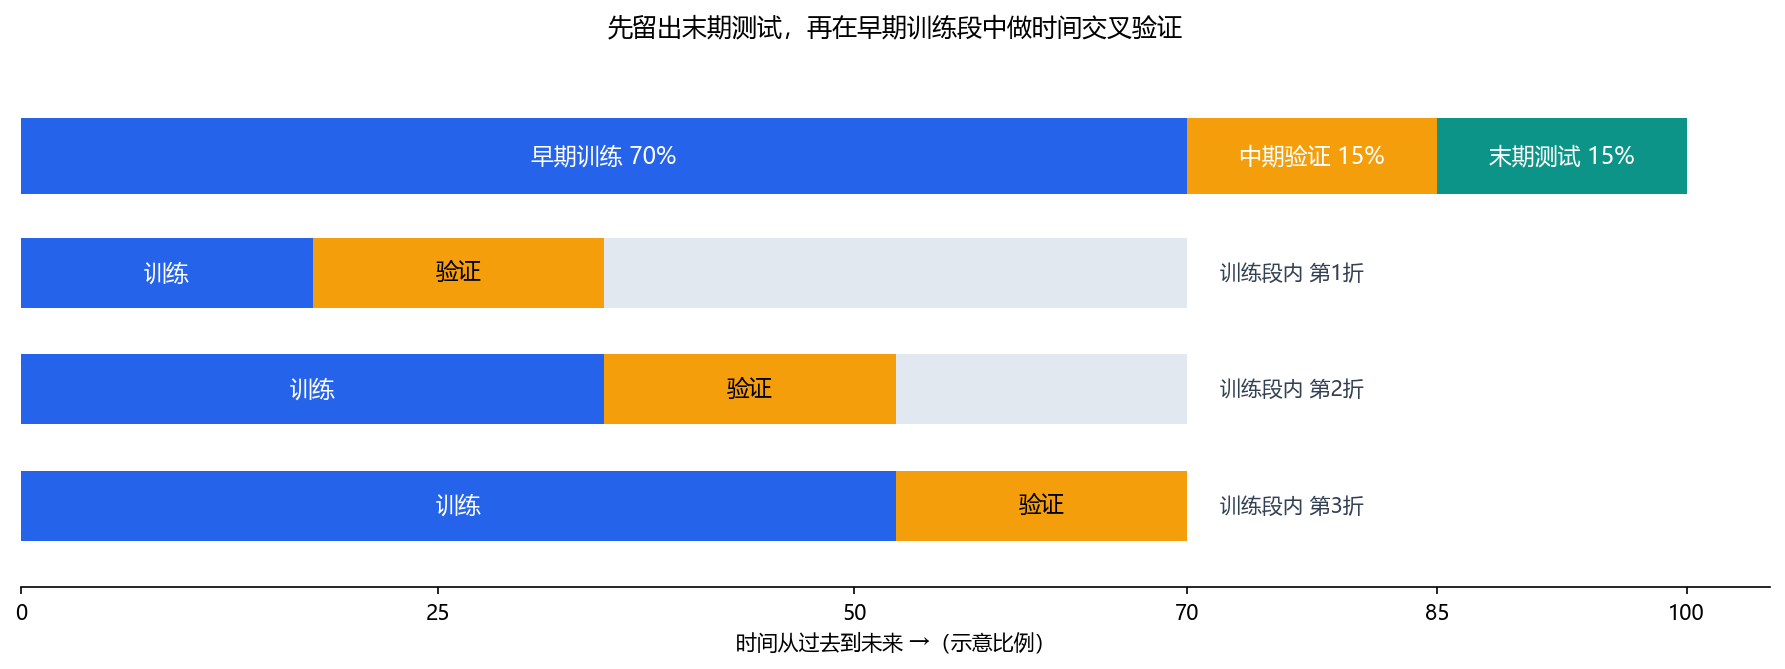

上图是本文自绘的流程示意，不是课程数据分布。

```python
# 边界按原始时间网格确定，不因缺失行被dropna而悄悄移动。
n_hours = len(hourly)
valid_start = hourly.index[int(n_hours * 0.70)]
test_start = hourly.index[int(n_hours * 0.85)]
train = table.loc[table.index < valid_start]
valid = table.loc[(table.index >= valid_start) & (table.index < test_start)]
test = table.loc[table.index >= test_start]
if min(len(train), len(valid), len(test)) == 0:
    raise ValueError("某一时间段没有完整样本，请调整边界或检查缺失")

X_train, y_train = train[FEATURE_COLUMNS], train["power_load"]
X_valid, y_valid = valid[FEATURE_COLUMNS], valid["power_load"]
X_test, y_test = test[FEATURE_COLUMNS], test["power_load"]
assert train.index.max() < valid.index.min() < test.index.min()
print("训练/验证/测试行数：", len(train), len(valid), len(test))
print("验证起点：", valid_start, "测试起点：", test_start)
```

特征表可以在时间切分前计算，因为本函数只读取过去，且没有从全量数据拟合统计参数。验证/测试行使用其之前已到达的真实负荷，表示**逐小时滚动一步预测**；不能把这种结果解释为固定起点的多步成绩。

是否需要 `gap` 取决于标签覆盖范围和数据延迟。当前标签是单个小时点，历史及时到达，示例 `gap=0`；若标签是未来 24 小时总量，训练标签区间可能跨进验证段，需要按覆盖范围留间隔。


## 11. 回归评价：MAE、MSE、RMSE与相对误差

令 $e_i=y_i-\hat y_i$，则：

$$MAE=\frac1N\sum_i|e_i|,\qquad
MSE=\frac1N\sum_i e_i^2,\qquad
RMSE=\sqrt{MSE}$$

MAE 和 RMSE 与负荷同单位，MSE 是平方单位。RMSE 更强调较大误差，但不能只凭其中一个指标评价业务效果。

$$MAPE=\frac{100\%}{N}\sum_i\left|\frac{y_i-\hat y_i}{y_i}\right|$$

MAPE 在真值为零时无定义，接近零时很不稳定。本文主要用 MAE/RMSE，并补充：

$$WAPE=100\%\cdot\frac{\sum_i|y_i-\hat y_i|}{\sum_i|y_i|}$$

WAPE 不是各点百分误差的简单平均；总负荷为零时也无定义。还应分小时、峰谷、节假日查看误差。课程代码注释里的 MAPE 与实际调用的 `mean_squared_error` 不一致，**以实际公式和 API 为准**。

```python
def regression_metrics(y_true, y_pred):
    true = np.asarray(y_true, dtype=float)
    pred = np.asarray(y_pred, dtype=float)
    if true.ndim != 1 or true.shape != pred.shape or true.size == 0:
        raise ValueError("真值与预测需为形状一致的非空一维数组")
    if not np.isfinite(true).all() or not np.isfinite(pred).all():
        raise ValueError("评价输入存在非有限值")
    mse = mean_squared_error(true, pred)
    denominator = np.abs(true).sum()
    return {
        "MAE": mean_absolute_error(true, pred),
        "MSE": mse,
        "RMSE": np.sqrt(mse),
        "WAPE(%)": 100 * np.abs(true - pred).sum() / denominator
                   if denominator > 0 else np.nan,
    }

baseline_valid = pd.DataFrame({
    "前一小时": regression_metrics(y_valid, valid["lag_1"]),
    "昨日同刻": regression_metrics(y_valid, valid["yesterday_load"]),
    "过去24小时均值": regression_metrics(y_valid, valid["roll24_mean"]),
}).T
print("验证集基线：")
print(baseline_valid.round(3))
```

所有模型必须评价同一组时间戳。若缺失处理导致样本不同，需要对齐后再比较。


## 12. 用 XGBoost 做负荷回归

XGBoost 将多棵树的输出相加。平方误差下，新树根据当前预测残差的梯度信息改进结果；正则项和采样可以限制复杂度。它并不自动理解“未来”，时序信息来自我们制作的特征。

| 参数 | 含义 | 本例使用 |
| --- | --- | --- |
| `objective` | 回归目标函数 | `reg:squarederror` |
| `n_estimators` | 提升树数量 | 候选 100、150 |
| `max_depth` | 单树最大深度 | 候选 3、6 |
| `learning_rate` | 每棵树的贡献步长 | 0.1 |
| `subsample` / `colsample_bytree` | 行 / 列采样比例 | 1.0，便于复现实验 |
| `reg_lambda` | L2 正则 | 1.0 |
| `tree_method` | 建树方式 | `hist` |
| `random_state` / `n_jobs` | 随机种子 / 线程数 | 42 / 1 |

教师初始参数为 `n_estimators=150, max_depth=6, learning_rate=0.1`。本文把它作为候选之一，并与较浅的树比较；并未宣称这些数值是电力业务的最优配置。

树对训练范围之外的趋势外推通常有限。随着用电结构变化，即使小时规律相似，也可能需要重训练或加入趋势特征。


## 13. 时间交叉验证选择参数

`TimeSeriesSplit` 每折使用较早的数据训练、较晚的数据验证，训练窗口逐渐扩展。本文在训练段内比较两套候选参数；中间验证段用来检查候选模型与基线，最后测试段只在方案确定后评价。

```python
tscv = TimeSeriesSplit(n_splits=3)
base_model = XGBRegressor(
    objective="reg:squarederror",
    learning_rate=0.1,
    subsample=1.0, colsample_bytree=1.0,
    reg_lambda=1.0, tree_method="hist",
    random_state=42, n_jobs=1,
)
param_grid = [
    {"n_estimators": [100], "max_depth": [3]},
    {"n_estimators": [150], "max_depth": [6]},
]
search = GridSearchCV(
    base_model, param_grid=param_grid, cv=tscv,
    scoring="neg_mean_absolute_error", n_jobs=1, refit=True,
)
search.fit(X_train, y_train)
candidate = search.best_estimator_
cv_table = pd.DataFrame(search.cv_results_)[
    ["params", "mean_test_score", "std_test_score"]
].copy()
cv_table["平均验证MAE"] = -cv_table["mean_test_score"]
print(cv_table[["params", "平均验证MAE", "std_test_score"]].to_string(index=False))
print("选中参数：", search.best_params_)
candidate_valid_metrics = regression_metrics(y_valid, candidate.predict(X_valid))
print("中间验证段：", candidate_valid_metrics)
```

sklearn 的评分遵循“越大越好”，因此 MAE 用负值返回，显示误差时再取负号。交叉验证标准差反映不同时间段的差异，不能解释成严格的未来误差置信区间。

`TimeSeriesSplit` 按行切分；若 `dropna` 后有长时间缺口，各折覆盖的实际时长可能不同。真实项目可用明确的日期区间滚动回测，并保证每折覆盖合适的季节和业务周期。

若使用 early stopping，`eval_set` 也必须来自该折训练末端，不能把最终测试集作为提前停止的依据。本例为便于复现，不使用 early stopping。


## 14. 确定方案后重训，评价末期测试段

参数确定后，可以用训练段和中间验证段共同训练最终模型，再评价保留的末期测试段。测试期间输入每个目标之前已经观测到的真实历史负荷，因此此处评价的是滚动一步。

```python
from sklearn.base import clone

development = pd.concat([train, valid])
model = clone(candidate)
model.fit(development[FEATURE_COLUMNS], development["power_load"])
test_prediction = pd.Series(
    model.predict(X_test), index=X_test.index, name="prediction")
test_metrics = regression_metrics(y_test, test_prediction)
test_scores = pd.DataFrame({
    "前一小时": regression_metrics(y_test, test["lag_1"]),
    "昨日同刻": regression_metrics(y_test, test["yesterday_load"]),
    "XGBoost": test_metrics,
}).T
print("合成数据末期测试段，滚动一步：")
print(test_scores.round(3))

view = y_test.index[:24 * 7]
fig, axes = plt.subplots(2, 1, figsize=(12, 7))
axes[0].plot(view, y_test.loc[view], label="真实合成负荷", linewidth=1.8)
axes[0].plot(view, test_prediction.loc[view], label="XGBoost滚动一步", alpha=0.85)
axes[0].set_title("末期测试段前7天")
axes[0].set_ylabel("演示负荷单位")
axes[0].legend()
axes[1].bar(test_scores.index, test_scores["MAE"],
            color=["#94a3b8", "#f59e0b", "#2563eb"])
axes[1].set_title("同一测试时间段的MAE")
axes[1].set_ylabel("演示负荷单位")
fig.suptitle("合成数据实验，不能解释为南方电网真实成绩")
fig.tight_layout()
plt.show()
```

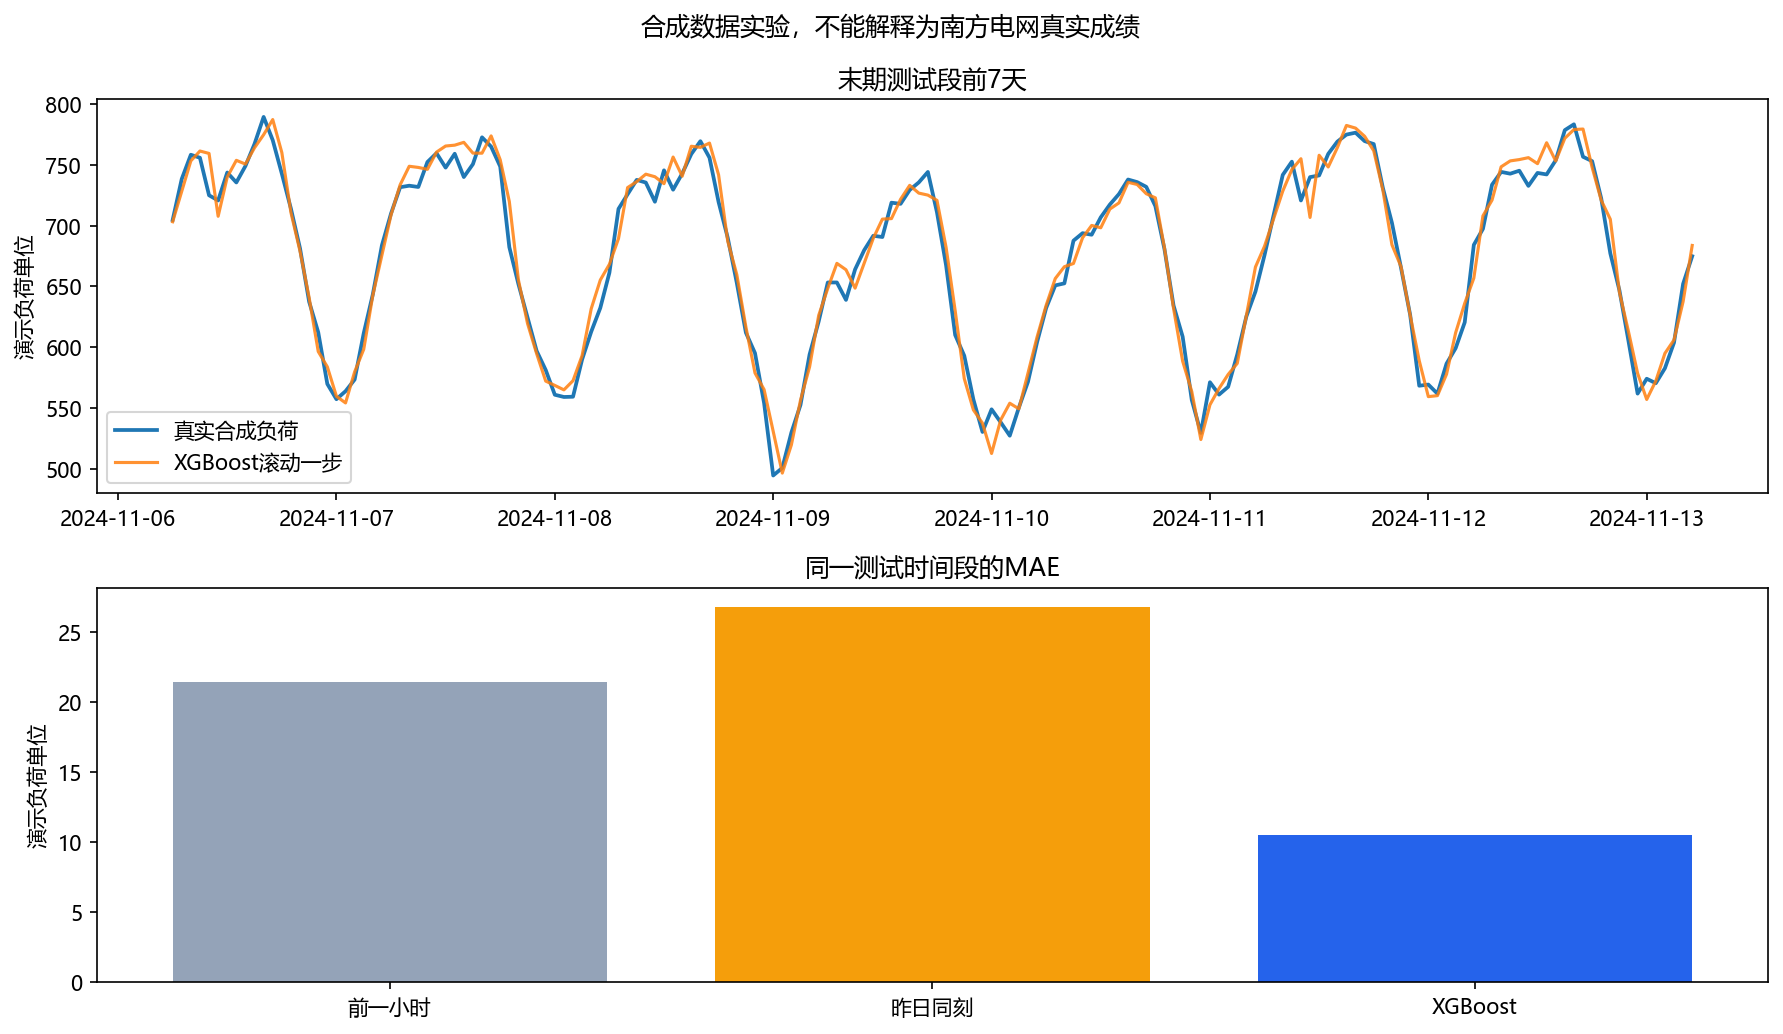

如果模型未超过简单基线，也应如实保留结果，先检查特征、数据口径、季节漂移和目标定义，再决定是否增加复杂度。

本次合成数据的实测结果（末期测试1314小时，滚动一步）：

| 方法 | MAE | RMSE | WAPE(%) |
| --- | --- | --- | --- |
| 前一小时 | 21.400 | 26.430 | 3.096 |
| 昨日同刻 | 26.778 | 35.331 | 3.874 |
| XGBoost | 10.520 | 13.325 | 1.522 |

MAE/RMSE 的单位为演示负荷单位。该结果来自本文固定种子的合成数据；不能换算成真实电网收益或用于宣传真实预测效果。


## 15. 看误差结构，避免只报一个总分

```python
error_frame = pd.DataFrame({
    "actual": y_test, "pred": test_prediction,
    "error": y_test - test_prediction,
})
error_frame["abs_error"] = error_frame["error"].abs()
hour_mae = error_frame.groupby(error_frame.index.hour)["abs_error"].mean()
print("平均有符号误差（正值表示整体低估）：", error_frame["error"].mean())
print("逐小时MAE：", hour_mae.round(2).to_dict())

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
error_frame["error"].hist(bins=35, ax=axes[0], color="#0d9488")
axes[0].axvline(0, color="black", linewidth=1)
axes[0].set_title("残差分布：真值减预测")
axes[0].set_xlabel("演示负荷单位")
hour_mae.plot.bar(ax=axes[1], color="#2563eb", rot=0)
axes[1].set_title("目标小时与MAE")
axes[1].set_xlabel("小时")
axes[1].set_ylabel("演示负荷单位")
fig.suptitle("合成数据末期测试段的误差分析")
fig.tight_layout()
plt.show()
```

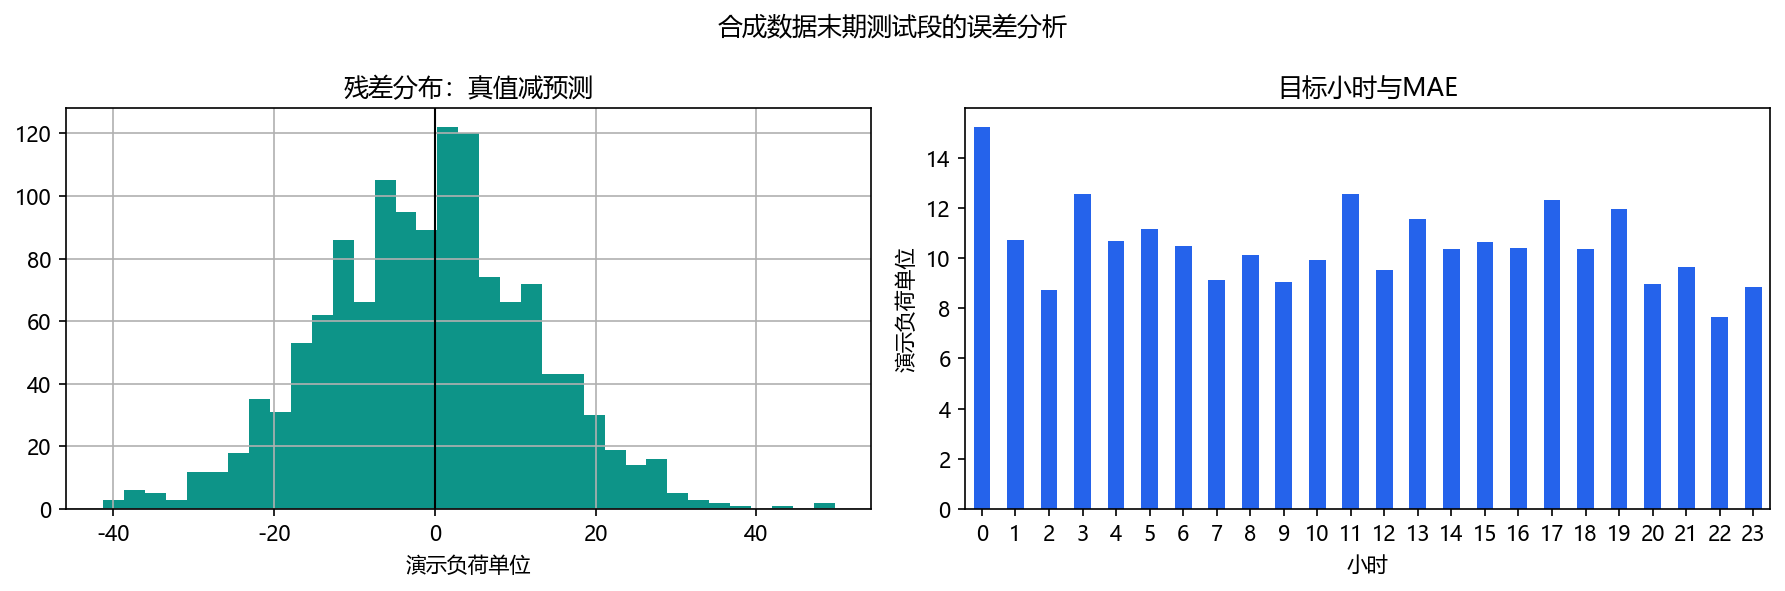

继续关注峰值低估、谷值高估、周一与周末切换、连续偏差和缺失区域。如果据测试结果继续改模型，这段测试就已经参与开发，下一版应准备新的独立时间段。


## 16. 单时刻预测：只取目标之前的历史

教师预测代码逐次保留 `< pred_time` 的负荷，这个时间边界是关键；但缺历史时直接填 `600` 没有充分依据。本篇要求最近 24 个小时完整，否则明确报错。

为了保证训练与推理一致，单时刻特征也调用 `build_features`。目标位置先放 `NaN`，它只用于建立索引，不会读取真实目标。

```python
def one_row_features(history, target_time):
    t = pd.Timestamp(target_time)
    if t.tzinfo is not None or t != t.floor("h"):
        raise ValueError("目标必须是统一时区口径下的无时区整点")
    if not isinstance(history.index, pd.DatetimeIndex):
        raise ValueError("历史数据需要DatetimeIndex")
    if history.index.tz is not None or not history.index.is_unique:
        raise ValueError("历史时间必须无时区且无重复")
    past = history.loc[history.index < t].sort_index()
    required_times = pd.date_range(t - pd.Timedelta(hours=24), periods=24, freq="h")
    window = past.reindex(required_times)
    values = pd.to_numeric(window, errors="raise").to_numpy(dtype=float)
    if not np.isfinite(values).all() or (values < 0).any():
        raise ValueError(f"{t} 前24小时缺少有效负荷，需补齐或采用已定义的降级方案")
    placeholder = pd.Series([np.nan], index=pd.DatetimeIndex([t]))
    series = pd.concat([window, placeholder]).astype(float)
    row = build_features(series).loc[[t], FEATURE_COLUMNS]
    if row.isna().any().any():
        raise ValueError("推理特征不完整")
    return row

def predict_one(fitted_model, history, target_time):
    row = one_row_features(history, target_time)
    return float(fitted_model.predict(row)[0])

first_target = X_test.index[0]
history_before_test = hourly.loc[hourly.index < first_target, "power_load"]
inference_row = one_row_features(history_before_test, first_target)
np.testing.assert_allclose(inference_row.to_numpy(), X_test.loc[[first_target]].to_numpy())
one_prediction = predict_one(model, history_before_test, first_target)
print("预测时刻：", first_target, "标量预测：", one_prediction)
```

返回 `float`，避免把形如 `array([值])` 的数组写进结果列。实际服务还应检查历史负荷单位、取值范围和模型版本。


## 17. 滚动一步回测：预测后再接收真实值

在测试段的每个时刻：

1. 取之前已经到达的真实历史。
2. 预测当前负荷并记录结果。
3. 观测当前真实值后，把它加入历史。
4. 移动到下一个小时。

```python
def backtest_one_step(fitted_model, actual_series, targets):
    targets = pd.DatetimeIndex(targets).sort_values()
    if targets.empty or not targets.is_unique:
        raise ValueError("待预测时间必须非空且唯一")
    if len(targets) > 1 and not (np.diff(targets.asi8) == pd.Timedelta(hours=1).value).all():
        raise ValueError("本示例要求逐小时连续回测")
    history = actual_series.loc[actual_series.index < targets[0]].copy()
    predictions = []
    for t in targets:
        predictions.append(predict_one(fitted_model, history, t))
        observed = float(actual_series.loc[t])  # 只能在当前预测完成后加入
        if not np.isfinite(observed):
            raise ValueError("新观测缺失，需要显式定义后续预测策略")
        history.loc[t] = observed
    return pd.Series(predictions, index=targets, name="rolling_prediction")

rolling_targets = X_test.index[:72]
rolling_preds = backtest_one_step(model, hourly["power_load"], rolling_targets)
np.testing.assert_allclose(
    rolling_preds.to_numpy(), test_prediction.loc[rolling_targets].to_numpy(),
    rtol=1e-6, atol=1e-5,
)
print("逐小时服务式回测与批量因果特征预测一致")
print(regression_metrics(y_test.loc[rolling_targets], rolling_preds))
```

上面的批量测试等价模拟的是每次预测前更新历史的情形。实际数据有上报延迟时，两者还需统一观测到达规则。


## 18. 固定起点预测未来24小时：递归与直接预测

| 策略 | 固定起点之后的历史负荷怎么获得？ | 主要代价 |
| --- | --- | --- |
| 递归多步 | 把前一步预测值写回历史 | 误差会传递，越往后越依赖预测 |
| 直接多步 | 针对不同跨度训练独立模型 | 模型更多，各跨度样本需对齐 |
| 多输出模型 | 一次输出未来多个目标 | 标签形状和窗口需重新设计 |
| 滚动一步 | 每小时获得新真值后再预测 | 依赖实时观测，不能代替一次性24小时预测 |

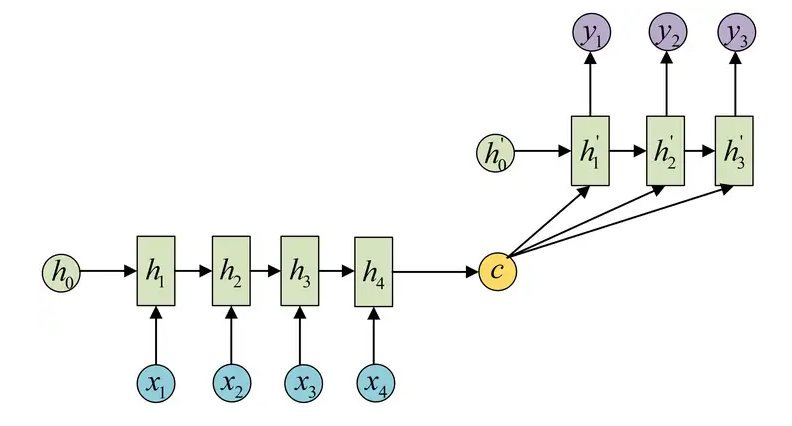

*课程图展示编码器把历史表示为上下文、解码器生成多步输出。它是另一种模型结构，本篇没有训练或宣称验证 seq2seq。*

递归预测可以复用当前一步模型，但训练时历史列来自真值，后续推理时部分历史来自预测，会出现分布差异。未来日历已知，未来真实负荷未知；天气特征也只能用当时可获取的天气预报。


### 18.1 递归预测示例与两种评价条件

```python
def forecast_recursive(fitted_model, history, start_time, steps=24):
    if not isinstance(steps, int) or steps < 1:
        raise ValueError("steps必须为正整数")
    start = pd.Timestamp(start_time)
    # 即使传进了完整数据，也排除起点及之后的真值。
    working_history = history.loc[history.index < start].copy()
    targets = pd.date_range(start, periods=steps, freq="h")
    results = []
    for t in targets:
        estimate = predict_one(fitted_model, working_history, t)
        results.append(estimate)
        working_history.loc[t] = estimate  # 写回的是预测值
    return pd.Series(results, index=targets, name="recursive_prediction")

start = X_test.index[0]
recursive_preds = forecast_recursive(model, history_before_test, start, steps=24)
targets_24 = recursive_preds.index
rolling_24 = backtest_one_step(model, hourly["power_load"], targets_24)
np.testing.assert_allclose(recursive_preds.iloc[0], rolling_24.iloc[0], atol=1e-5)

conditions = pd.DataFrame({
    "滚动一步（每小时更新真值）":
        regression_metrics(hourly.loc[targets_24, "power_load"], rolling_24),
    "固定起点递归24小时":
        regression_metrics(hourly.loc[targets_24, "power_load"], recursive_preds),
}).T
print(conditions.round(3))

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(targets_24, hourly.loc[targets_24, "power_load"], label="真实合成负荷", marker="o")
ax.plot(targets_24, rolling_24, label="滚动一步", marker=".")
ax.plot(targets_24, recursive_preds, label="固定起点递归24小时", marker=".")
ax.set_title("合成数据：预测条件不同，分数不能混为一谈")
ax.set_ylabel("演示负荷单位")
ax.legend()
fig.tight_layout()
plt.show()
```

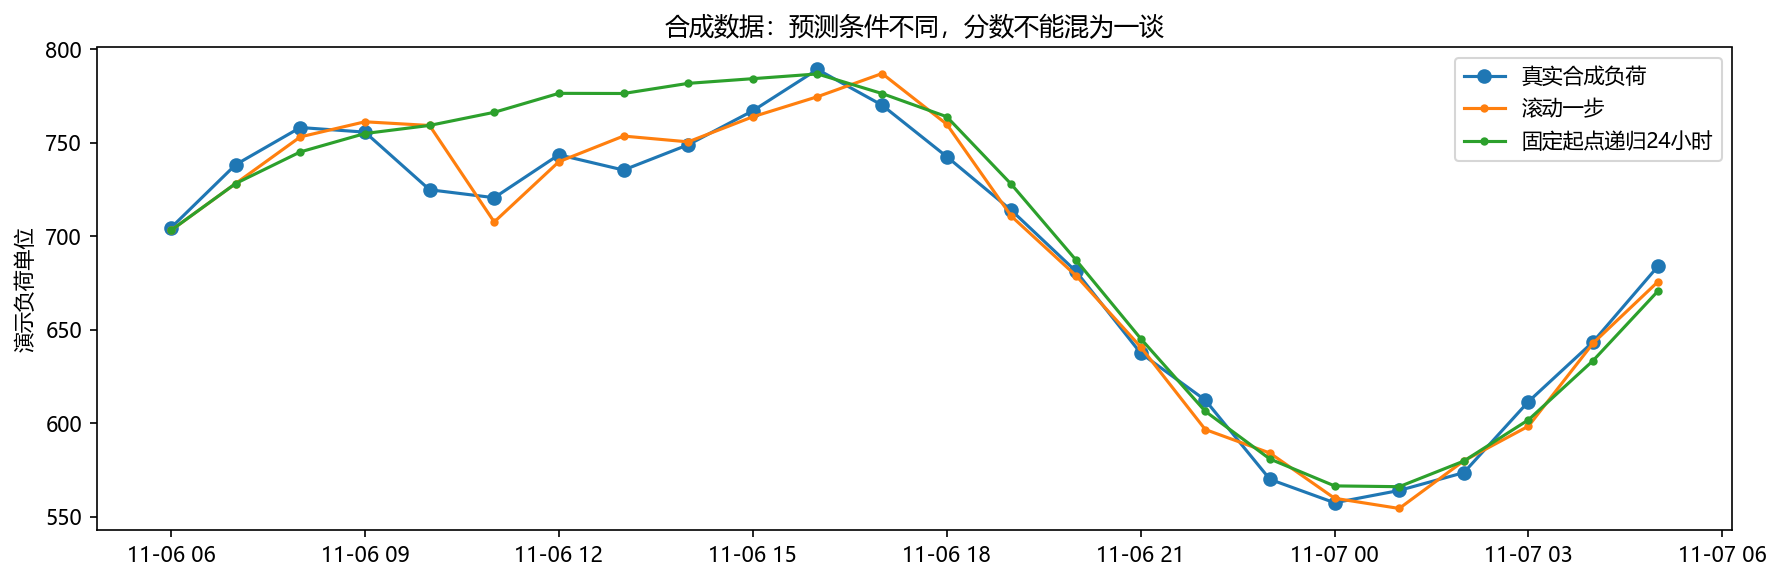

真值只在上述代码的评价和绘图部分使用。这个 24 小时例子用于说明条件差异，不足以证明两种策略在全年哪个更好；多步方案需要在多个固定起点分别回测，并按预测跨度统计误差。

同一段24小时、不同预测条件的本次演示结果：

| 方法 | MAE | RMSE | WAPE(%) |
| --- | --- | --- | --- |
| 滚动一步（每小时更新真值） | 9.331 | 12.107 | 1.353 |
| 固定起点递归24小时 | 14.751 | 19.488 | 2.139 |

这个单起点结果只用于说明可用信息条件差异。


## 19. 保存模型时同时保存特征约定

只有 `xgb.pkl` 无法完整说明怎样生成输入。至少保存列名顺序、频率、窗口长度、目标、数据来源和版本；真正部署还要打包同版本的特征代码、数据接口与环境。

```python
import joblib
import sklearn
import xgboost

bundle = {
    "model": model,
    "feature_columns": FEATURE_COLUMNS,
    "feature_recipe": "hourly-causal-v1",
    "frequency": "h",
    "lookback_hours": 24,
    "target": "当前目标时刻负荷，使用其之前已到达的历史",
    "data_source": data_source,
    "test_metrics_one_step": test_metrics,
    "versions": {
        "pandas": pd.__version__, "sklearn": sklearn.__version__,
        "xgboost": xgboost.__version__,
    },
}
model_dir = Path("model")
model_dir.mkdir(parents=True, exist_ok=True)
model_path = model_dir / "power_load_bundle.joblib"
joblib.dump(bundle, model_path)
loaded = joblib.load(model_path)  # 只加载可信来源的模型文件
if loaded["feature_recipe"] != "hourly-causal-v1":
    raise ValueError("特征版本不一致")
if loaded["feature_columns"] != FEATURE_COLUMNS:
    raise ValueError("特征列顺序不一致")
loaded_prediction = predict_one(loaded["model"], history_before_test, first_target)
np.testing.assert_allclose(loaded_prediction, one_prediction, atol=1e-5)
print("模型与特征约定保存、加载、预测一致：", model_path)
```

one-hot 列顺序不能在预测时凭记忆硬编码；应按保存的约定生成并校验。对跨环境长期保存，可考虑 XGBoost 原生 JSON/UBJSON 模型格式并另外保存特征约定，同时验证兼容性。


## 20. 工程细节：日志、路径、缓存与上线监控

| 问题 | 建议做法 |
| --- | --- |
| 相对路径依赖启动目录 | 统一项目根目录；脚本中可用 `Path(__file__).resolve()`，Notebook 显式设置路径 |
| 模型或日志目录不存在 | 写文件前创建父目录 |
| 重复初始化 logger | 避免每次实例化都新增 FileHandler；统一配置和 handler 生命周期 |
| 日志编码与异常 | 指定 UTF-8，记录异常堆栈、目标时间和数据状态 |
| 每次预测扫描全部字典 | 维护最近必要历史窗口，按时间索引取值 |
| 模型加载频繁 | 服务启动时加载，再按版本受控更新 |
| 历史缓存 | 本例至少24小时；扩展周滞后时需保存更长窗口 |
| Redis 等缓存 | 保证地区键、时间戳、排序、过期策略和缺失处理一致 |
| 接口返回 | 标量值、目标时刻、模型版本、数据新鲜度、预测条件 |
| 上线监控 | 新数据延迟、缺失率、单位变化、MAE/RMSE、峰值误差与漂移 |

预测 API 可与训练流程解耦，容器化用于固定环境。缓存或服务框架不会自动修复时间泄漏；首要问题仍是每个特征在预测时是否已经可用。

遇到缺历史，可拒绝预测、等待数据、使用经过回测的季节基线或因果填充方案。降级结果要有标记，不能无依据填一个固定常数并混进正常预测成绩。


## 21. 进一步改进：按问题选择方法

- **更多历史特征：**前 24/48/168 小时、过去 6/24/168 小时统计、与昨日同刻的差值；先确认数据频率和窗口可用性。
- **外部变量：**节假日与调休、天气预报、地区属性、工业/居民用电占比。未来实测温度不能替代预测发起时的天气预报。
- **更合适的验证：**跨季节、节假日、高峰负荷和极端天气分别回测，使用实际观测到达时间。
- **地区分群：**可以先探索聚类再分组建模，但聚类和分组规则也要在训练期确定，避免利用未来结构。
- **模型比较：**线性回归、随机森林、LightGBM、RNN、iTransformer 等，在同一预测条件下比较；模型名字不保证效果。
- **组合模型：**Bagging 可减小波动；Stacking 必须用时间顺序生成的折外预测训练次级模型。
- **输出不确定性：**预测区间、分位数回归等需验证覆盖率，并关注不同季节与预测跨度。

特征重要性只是模型依赖的线索，不代表因果贡献。相关的滞后列会分摊重要性；随机打乱时序列还可能破坏其结构，解释结果要结合时间块和业务判断。


## 22. 换成课程CSV时的步骤

1. 使用第 6 节入口分别读取并检查 `train.csv`、`test.csv`，记录开始/结束时间、行数、频率和缺失率。
2. 从 `train.csv` 的末期留出验证段，在更早的训练段使用时间交叉验证选参数；`test.csv` 不参与调参。
3. 确认教师实际评价的预测起点。教师示例从 `2015-08-01 00:00:00` 开始，这只是课程给定时刻，应核对 CSV 覆盖范围后使用。
4. 若测试文件包含起点之前的历史上下文，把它用于制作滞后特征；同一时间与训练文件重叠时核对负荷是否一致，不能覆盖冲突。
5. 合并已确认的历史，建立小时网格，再提取特征；按明确日期边界选目标样本。未来标签始终不参与当前特征。
6. 滚动一步允许预测后接收新真值；固定起点多步必须递归或使用专门的多步模型。按业务场景选择评价方式。
7. 与持续性、昨日同刻等基线比较，报告样本数、过滤比例、时间段和单位。

课程 CSV 未取得时，不能把第 14 节合成数据分数写成“南方电网预测准确率”。回归也不能仅凭一条折线相似就声称准确。


## 23. 易错点速查

| 易错做法 | 后果 / 正确处理 |
| --- | --- |
| 时序随机切分、普通 KFold | 训练可能使用未来；按时间切分与滚动验证 |
| 有时间缺口直接 shift | 前一行不等于前一小时；先建立规则网格 |
| 只做整行去重 | 同一时间不同负荷还存在；单独检查时间戳冲突 |
| 把 datetime 转成字符串长期计算 | 时间运算、频率和时区处理更易出错；保持 datetime |
| rolling 未先 shift，或 center=True | 可能使用当前标签或未来；严格只用过去 |
| 用全年均值填训练缺失 | 读入未来信息；在训练折内拟合或用因果策略 |
| 用未来实测天气预测未来负荷 | 信息泄漏；用当时可获得的天气预报 |
| 训练和推理分别制作 one-hot | 列数、列序不一致；固定类别与统一函数 |
| 缺历史直接填600 | 无业务依据；显式缺失策略与降级标记 |
| 将预测数组直接塞入结果列表 | 得到 object/数组列；取 `float(pred[0])` |
| 注释写MAPE，实际调用MSE | 指标含义与单位错；核对公式和 API |
| 滚动一步当作未来24小时成绩 | 可用信息不同；分别报告起点与跨度 |
| 保存模型却不保存特征约定 | 难以复现输入；同步保存版本、列顺序和窗口 |
| 反复按测试段调参 | 测试变成开发数据；另留未来独立时间段 |


## 24. 练习与参考思路

1. 数据只有 09:00 和 11:00 两行，直接 `.shift(1)` 得到的是什么？  
   **答：**11:00 的前一行是 09:00，不能叫前一小时；补小时网格后 10:00 应为缺失。

2. 为什么 `shift(1).rolling(24)` 比 `rolling(24)` 更适合当前目标？  
   **答：**前者只包含 $t-24$ 到 $t-1$，后者包含当前 $y_t$，会混入标签。

3. 想在凌晨一次预测当天24小时，可以用当天10:00真实负荷预测11:00吗？  
   **答：**在凌晨发起时不可用；递归方案应使用已生成的预测值，或训练直接多步模型。

4. 小时和月份的列数固定后，未见过的月份是否就能预测准确？  
   **答：**固定列解决输入结构，不能保证未见类别和季节漂移的泛化。

5. 为什么需要昨日同刻基线？  
   **答：**负荷常有日周期；复杂模型需要证明相对这种简单规律的实际增益。

6. 为本例增加 `lag_168` 后，线上至少需要多少历史？  
   **答：**需有目标前168小时对应观测；若同时用168小时完整滚动窗口，需连续168小时有效历史，并同步更新训练与推理逻辑。

7. 如何验证“没有偷看未来”？  
   **答：**像第9.1节一样修改当前及未来真值，当前特征应不变；再检查训练截止时间、外部数据发布时间和数据转换拟合范围。

可扩展实验：给合成数据删除一段小时记录，比较拒绝预测、有限向前填充和季节基线的覆盖率与误差，并如实标记各方法实际评价的样本范围。


## 25. 来源与验证范围

课程依据：`09_数据挖掘案例-南方电网电力负荷预测/02-笔记/数据挖掘案例-南方电网时序预测.md`；嵌入该目录 `assets` 中的监督学习表、负荷特征表、seq2seq 三张原图。课程 `03-代码/load_predict_project/load_predict_project/data` 已核对存在 `train.csv`、`test.csv`；本次未成功取得数据内容，未执行下载的课程项目或压缩包，也未逐段转录视频。

本文增加规则小时网格、时间戳冲突检查、严格滞后滚动特征、时间切分、TimeSeriesSplit、基线对比、统一训练/推理特征、滚动一步与递归多步区分，以及模型与特征约定同步保存。合成实验只用于验证这些流程能运行，不代表真实电网效果。

验证包括：Notebook 格式、全部 Python 代码块的顺序执行、手算特征、当前/未来值改动不影响当前特征、重复时间冲突、缺口与缺历史提示、训练推理特征一致、滚动回测一致、递归第一步一致、模型加载一致、图片附件解码和 HTML 显示。前 01—08 篇保持原内容。
